# Dados e Aprendizagem Automática 26/27
### Part IV

## **Logistic Regression using Titanic Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
%matplotlib inline

*Load the CSV - Titanic train*

In [2]:
train = pd.read_csv('titanic_train.csv')

**EDA**

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Missing Data**

<Axes: >

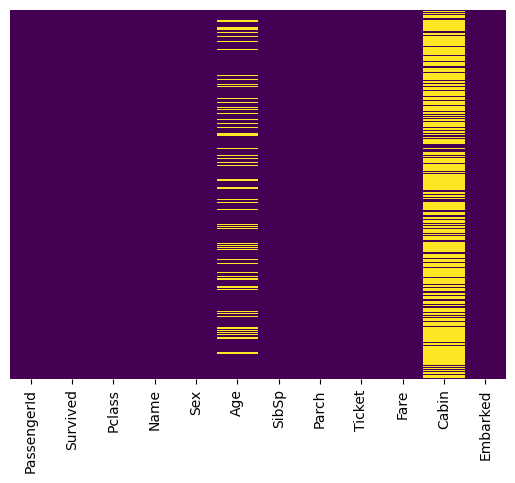

In [4]:
sns.heatmap(train.isnull(), yticklabels=False, cbar=False, cmap='viridis')

<Axes: xlabel='Survived', ylabel='count'>

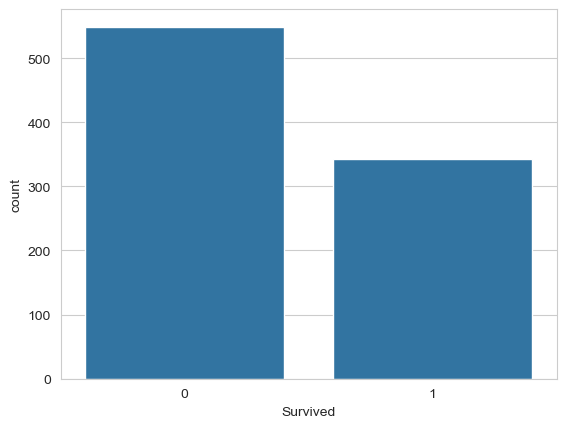

In [5]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data=train)

<Axes: xlabel='Survived', ylabel='count'>

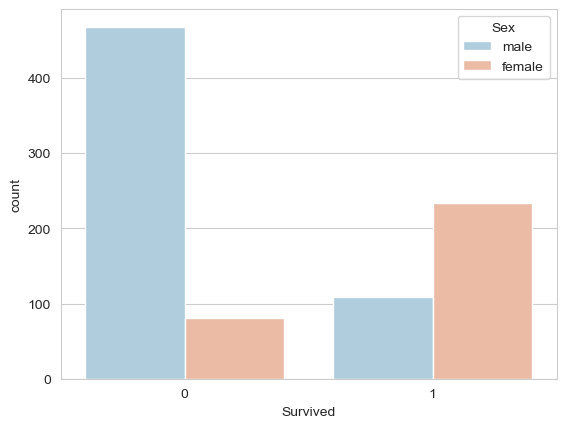

In [6]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Sex', data=train, palette='RdBu_r')

<Axes: xlabel='Survived', ylabel='count'>

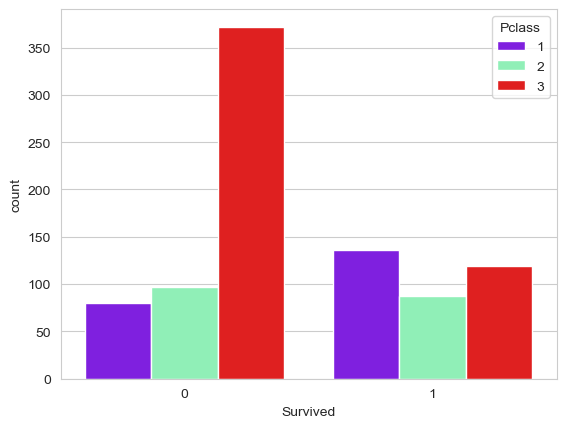

In [7]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Pclass', data=train, palette='rainbow')

<Axes: xlabel='Age', ylabel='Count'>

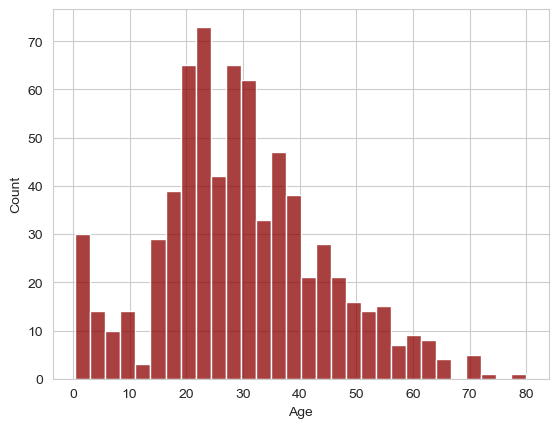

In [8]:
sns.histplot(train['Age'].dropna(), kde=False, color='darkred', bins=30)

In [ ]:
.hist(,color='darkred',alpha=0.7)

In [ ]:
sns.countplot(x='SibSp', data=train)

In [ ]:
train['Fare'].hist(color='green', bins=40, figsize=(8,4))

**Data Cleaning**

In [ ]:
plt.figure(figsize=(12, 7))
sns.boxplot(x='Pclass', y='Age', data=train)

In [ ]:
train['Age'] = train['Age'].fillna(train.groupby('Pclass')['Age'].transform('median'))

In [ ]:
sns.heatmap(train.isnull(), yticklabels=False,cbar=False,cmap='viridis')

Drop the <code>Cabin</code> column and the row in <code>Embarked</code> that is *NaN*:

In [ ]:
train.drop('Cabin',axis=1,inplace=True)

In [ ]:
train.head()

In [ ]:
train.dropna(inplace=True)

In [ ]:
train.describe()

**Converting Categorical Features**

In [ ]:
train.info()

In [ ]:
sex = pd.get_dummies(train['Sex'],drop_first=True)
embark = pd.get_dummies(train['Embarked'],drop_first=True)

In [ ]:
train.drop(['Sex', 'Embarked', 'Name', 'Ticket'],axis=1,inplace=True)

In [ ]:
train = pd.concat([train, sex, embark], axis=1)

In [ ]:
train.head()

**Logistic Regression Model**

In [ ]:
from sklearn.model_selection import train_test_split
X = train.drop('Survived',axis=1)
y = train['Survived']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y,
                                                    test_size=0.3, 
                                                    random_state=101)

In [ ]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data = pd.DataFrame(y_train,columns=['Survived']) )

In [ ]:
sns.set_style('whitegrid')
sns.countplot(x='Survived', data = pd.DataFrame(y_test,columns=['Survived']) )

<code>sklearn.linear_model.LogisticRegression(penalty='l2', *, dual=False, tol=0.0001, C=1.0, fit_intercept=True, intercept_scaling=1, class_weight=None, random_state=None, solver='lbfgs', max_iter=100, multi_class='deprecated', verbose=0, warm_start=False, n_jobs=None, l1_ratio=None)</code>

LogisticRegression' **solvers**:

- Small datasets, ‘liblinear’ is a good choice, whereas ‘sag’ and ‘saga’ are faster for large ones
- Multiclass problems, only ‘newton-cg’, ‘sag’, ‘saga’ and ‘lbfgs’ handle multinomial loss
- ‘liblinear’ is limited to one-versus-rest schemes.

Supported **penalties** by solver:

- ‘newton-cg’ - [‘l2’, ‘none’]

- ‘lbfgs’ - [‘l2’, ‘none’]

- ‘liblinear’ - [‘l1’, ‘l2’]

- ‘sag’ - [‘l2’, ‘none’]

- ‘saga’ - [‘elasticnet’, ‘l1’, ‘l2’, ‘none’]

In [ ]:
from sklearn.linear_model import LogisticRegression

**logmodel1 - LogisticRegression(random_state=2022, solver='newton-cg')**

In [ ]:
starttime = time.process_time()

logmodel1 = LogisticRegression(random_state=2022, solver='newton-cg')
print(logmodel1)
logmodel1.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

In [ ]:
predictions1 = logmodel1.predict(X_test)

**logmodel2 - LogisticRegression(random_state=2022, solver='lbfgs')**

In [ ]:
starttime = time.process_time()

logmodel2 = LogisticRegression(random_state=2022, solver='lbfgs', max_iter=800)
print(logmodel2)
logmodel2.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

In [ ]:
predictions2 = logmodel2.predict(X_test)

**logmodel3 - LogisticRegression(random_state=2022, solver='liblinear')**

In [ ]:
starttime = time.process_time()

logmodel3 = LogisticRegression(random_state=2022, solver='liblinear' )
print(logmodel3)
logmodel3.fit(X_train, y_train)

endtime = time.process_time()
print(f"Time spent: {endtime - starttime} seconds")

In [ ]:
predictions3 = logmodel3.predict(X_test)

**Evaluation**

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [ ]:
print("With 'newton-cg': \n", classification_report(y_test, predictions1))
print("With 'lbfgs': \n", classification_report(y_test, predictions2))
print("With 'liblinear': \n", classification_report(y_test, predictions3))

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions1)
ConfusionMatrixDisplay.from_predictions(y_test, predictions2)
ConfusionMatrixDisplay.from_predictions(y_test, predictions3)

Not so bad! You might want to explore other feature engineering and the other titanic_text.csv file, some suggestions for feature engineering:

* Try grabbing the Title (Dr.,Mr.,Mrs,etc..) from the name as a feature
* Maybe the Cabin letter could be a feature
* Is there any info you can get from the ticket?